# Experiment 2
## Contrast Enhancement and Histogram-Based Image Processing using Python and OpenCV

##  1. Import the required libraries, including OpenCV, NumPy, and Matplotlib.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load a low-contrast grayscale image or convert a color image into grayscale for processing


In [ ]:
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image could not be loaded.")
else:
    print("Image loaded successfully!")
    print("Filename:", filename)
    print("Image shape:", img.shape)

Saving photo.png to photo (1).png
Image loaded successfully!
Filename: photo (1).png
Image shape: (540, 473)


## 3. Display the original image and generate its histogram to analyze the distribution of pixel intensity values.



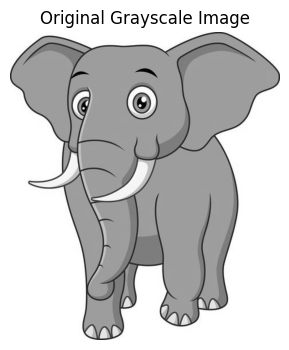

In [ ]:
plt.figure(figsize=(5, 4))

plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.show()

Histogram

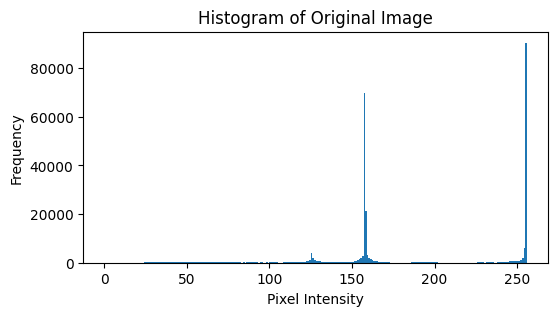

In [ ]:
plt.figure(figsize=(6, 3))

plt.hist(img.ravel(), bins=256, range=(0, 256))

plt.title("Histogram of Original Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

## 4. Perform contrast stretching to improve the dynamic range of pixel intensities.

In [ ]:

min_val = np.min(img)
max_val = np.max(img)

if max_val == min_val:
    contrast_stretched = img.copy()
else:
    contrast_stretched = (
        (img.astype(np.float32) - min_val)
        / (max_val - min_val)
        * 255
    ).astype(np.uint8)

print("Minimum intensity:", min_val)
print("Maximum intensity:", max_val)

Minimum intensity: 0
Maximum intensity: 255


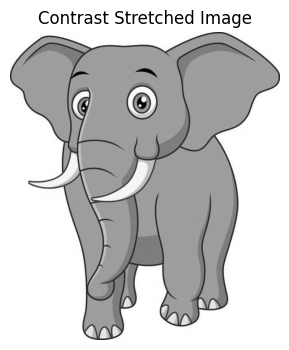

In [ ]:
plt.figure(figsize=(5, 4))

plt.imshow(contrast_stretched, cmap="gray")
plt.title("Contrast Stretched Image")
plt.axis("off")

plt.show()

Histogram of contrast-stretched image

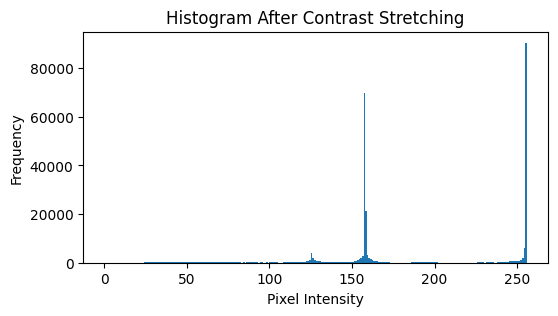

In [ ]:
plt.figure(figsize=(6, 3))

plt.hist(
    contrast_stretched.ravel(),
    bins=256,
    range=(0, 256)
)

plt.title("Histogram After Contrast Stretching")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

## 5. Apply Histogram Equalization using OpenCV and compare the enhanced image with the original image


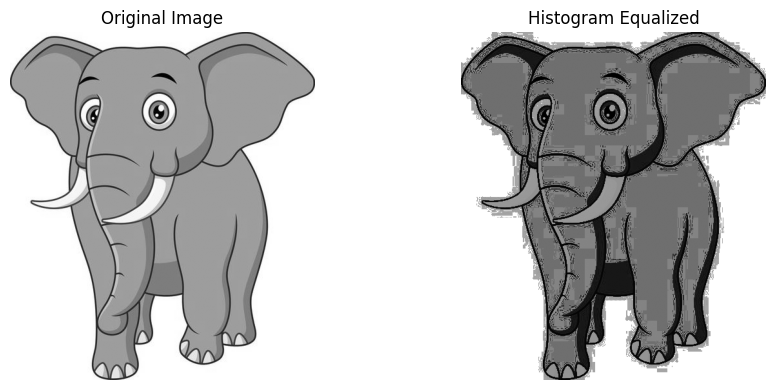

In [ ]:
equalized = cv2.equalizeHist(img)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Histogram Equalized")
plt.axis("off")

plt.tight_layout()
plt.show()

Comparison of original and equalized image

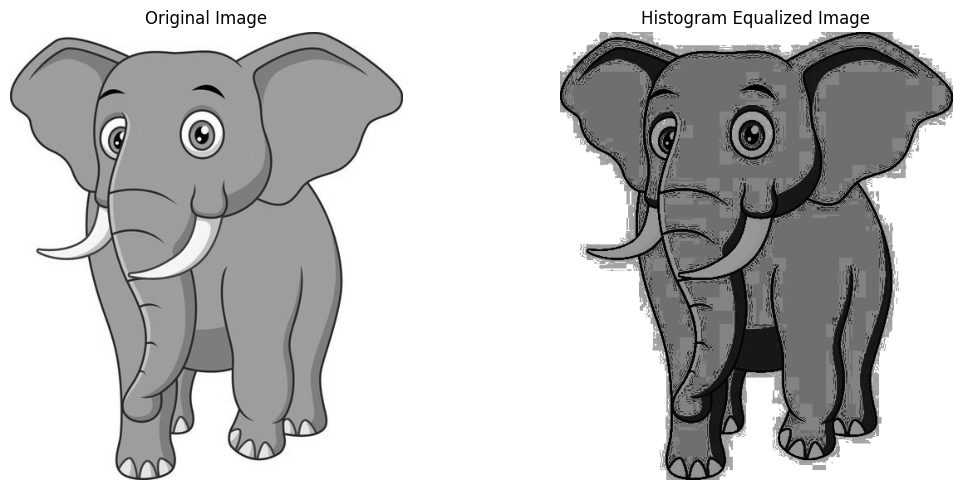

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Histogram Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## 6. Implement Contrast Limited Adaptive Histogram Equalization (CLAHE) and observe its performance on images with varying illumination.


In [ ]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_img = clahe.apply(img)

Comparing the images

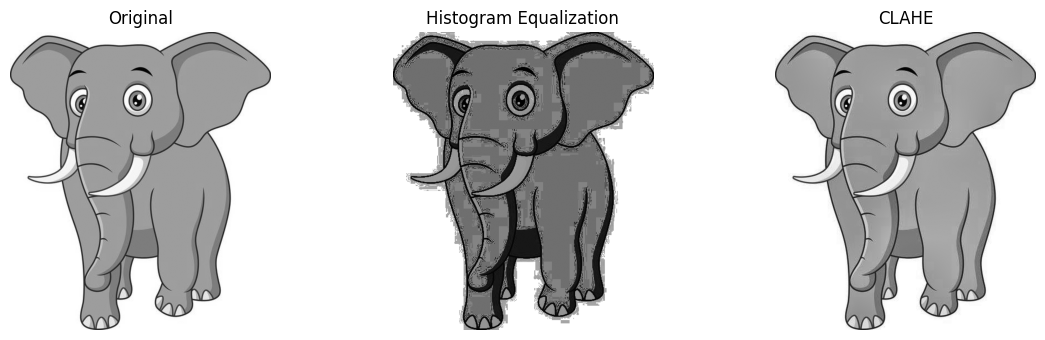

In [ ]:
plt.figure(figsize=(12, 3.5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_img, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Plot and compare the histograms of the original, histogram-equalized, and CLAHEenhanced images.

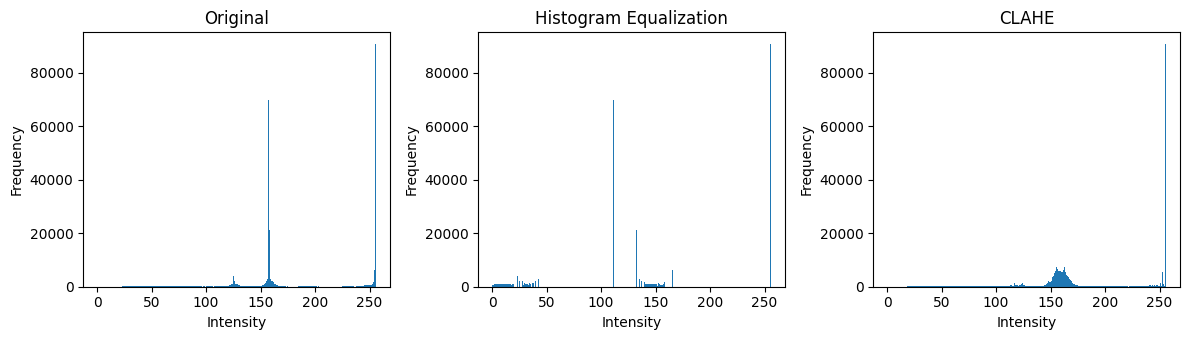

In [ ]:
plt.figure(figsize=(12, 3.5))

# Original
plt.subplot(1, 3, 1)
plt.hist(img.ravel(), bins=256, range=(0, 256))
plt.title("Original")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

# Histogram Equalization
plt.subplot(1, 3, 2)
plt.hist(equalized.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Equalization")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

# CLAHE
plt.subplot(1, 3, 3)
plt.hist(clahe_img.ravel(), bins=256, range=(0, 256))
plt.title("CLAHE")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## 8. Analyze the visual improvements in terms of brightness, contrast, and feature visibility.

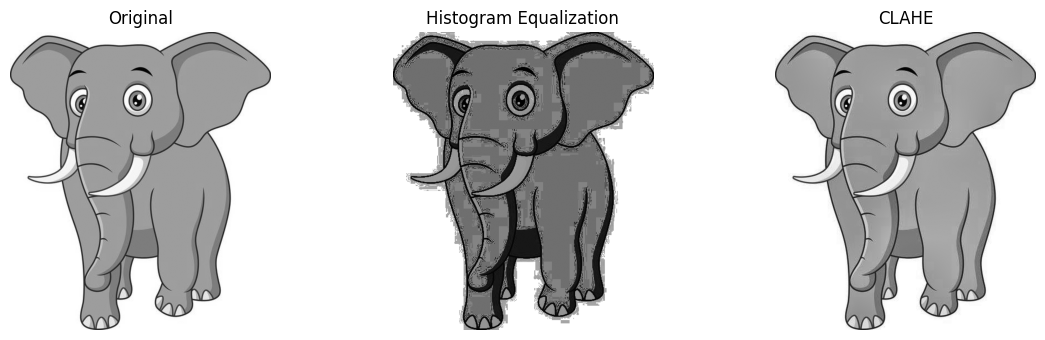

In [ ]:
plt.figure(figsize=(12, 3.5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_img, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Compare the effectiveness of Histogram Equalization and CLAHE for different types of images.


Histogram Equalization improves the overall contrast of the image but may sometimes over-enhance certain regions or noise. CLAHE performs local contrast enhancement and controls excessive amplification, making it more suitable for images with varying illumination.

## 10. Document the observations and discuss the role of histogram-based enhancement in computer vision applications.


### Overall Observation

The experiment demonstrated that histogram-based techniques can significantly improve the visual quality of low-contrast images.


Contrast stretching expands the dynamic range of pixel intensities. Histogram equalization improves the global contrast by redistributing intensity values. CLAHE provides adaptive local contrast enhancement and limits excessive contrast amplification.